In [1]:
# ===== Cell 1：检查环境 =====

import sys
print("Python 版本:", sys.version)
print("Python 位置:", sys.executable)   # 新增：显示当前用的是哪个 Python，用来确认是不是我们的新环境

# 把 tensorflow 换成了 torch（PyTorch）
for name in ["pandas", "numpy", "matplotlib", "sklearn", "xgboost", "torch"]:
    try:
        module = __import__(name)
        print(f"✅ {name} 已安装，版本 {module.__version__}")
    except Exception as e:                  # 改成 Exception：任何错误都能接住，不会像上次那样整个 cell 崩掉
        print(f"❌ {name} 出错: {type(e).__name__}")   # type(e).__name__ 会显示错误的类型名，方便判断问题

Python 版本: 3.12.16 (main, Nov 11 2026, 00:09:12) [Clang 23.1.3 ]
Python 位置: /Users/liusiming/electricity-forecasting/.venv/bin/python
✅ pandas 已安装，版本 3.1.1
✅ numpy 已安装，版本 2.5.5
✅ matplotlib 已安装，版本 3.11.2
✅ sklearn 已安装，版本 1.9.1
✅ xgboost 已安装，版本 3.4.1
✅ torch 已安装，版本 2.15.0


In [2]:
%%writefile .gitignore
# 告诉 git 哪些文件不要上传

# Python 虚拟环境（本机专用，体积大）
.venv/

# 原始数据（太大，从 UCI 官网下载）
data/

# Jupyter 自动生成的临时文件
.ipynb_checkpoints/
__pycache__/

# Mac 系统自动生成的文件
.DS_Store

Writing .gitignore


In [3]:
# ===== Cell 2：导入库 + 读取原始数据 =====

import pandas as pd               # 导入 pandas，起个简称 pd（行业惯例，以后都用 pd.xxx）
import numpy as np                # 导入 numpy，简称 np
import matplotlib.pyplot as plt   # 导入画图模块，简称 plt

DATA_PATH = "data/household_power_consumption.txt"   # 数据文件的路径，存成一个变量，以后要改只改这一处

df_raw = pd.read_csv(             # read_csv：读取文本表格文件，结果是一个 DataFrame（可以理解成 Python 里的 Excel 表）
    DATA_PATH,
    sep=";",                      # 这个文件的列与列之间用分号 ; 隔开（默认是逗号，所以必须指定）
    na_values="?",                # 原始数据里缺失值写成了 "?"，告诉 pandas 把 "?" 当成缺失值（NaN）
    low_memory=False,             # 一次性读完整个文件再判断每列的类型，避免类型判断出错的警告
)

print("数据形状（行数, 列数）:", df_raw.shape)   # shape 返回 (行数, 列数)
df_raw.head()                     # head() 显示前 5 行；放在 cell 最后一行会自动以表格形式显示

数据形状（行数, 列数）: (2075259, 9)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [4]:
# ===== Cell 3：合并 Date 和 Time，转换成数值 =====

df = df_raw.copy()                # copy()：复制一份，之后在 df 上改，不影响 df_raw

# 把 "16/12/2006" 和 "17:24:00" 拼成 "16/12/2006 17:24:00"，再转换成真正的时间类型
df["datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],      # 两列字符串中间加个空格拼起来
    format="%d/%m/%Y %H:%M:%S",         # 告诉 pandas 日期格式：日/月/年 时:分:秒（欧洲格式，日在前）
)

df = df.drop(columns=["Date", "Time"])  # 原来的两列已经合并了，删掉
df = df.set_index("datetime")           # 把 datetime 设为“索引”（行标签），时间序列分析的标准做法
df = df.sort_index()                    # 按时间从早到晚排序，保险起见

# 把所有测量列都转换成数值类型
df = df.apply(pd.to_numeric, errors="coerce")   # apply 对每一列执行 to_numeric；errors="coerce" 表示转不了的值变成 NaN，而不是报错

df.info()                         # info() 显示每列的名字、非空值个数、数据类型

<class 'pandas.DataFrame'>
DatetimeIndex: 2075259 entries, 2006-12-16 17:24:00 to 2010-11-26 21:02:00
Data columns (total 7 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Global_active_power    float64
 1   Global_reactive_power  float64
 2   Voltage                float64
 3   Global_intensity       float64
 4   Sub_metering_1         float64
 5   Sub_metering_2         float64
 6   Sub_metering_3         float64
dtypes: float64(7)
memory usage: 126.7 MB


In [5]:
# ===== Cell 4：检查缺失值、重复时间戳、时间间隔 =====

print("时间范围:", df.index.min(), "到", df.index.max())   # 最早和最晚的时间
print("总行数:", len(df))

print("\n每列缺失值个数:")         # \n 表示换行，让输出好看一点
print(df.isna().sum())           # isna() 判断每个值是否缺失（True/False），sum() 统计每列有几个 True

missing_rows = df.isna().all(axis=1)          # all(axis=1)：一整行全部缺失才算 True
print("\n整行都缺失的行数:", missing_rows.sum())
print("缺失比例: {:.2%}".format(missing_rows.mean()))   # mean() 求 True 的比例；{:.2%} 显示成百分比，保留两位小数

print("\n重复的时间戳个数:", df.index.duplicated().sum())   # duplicated() 找出重复出现的时间

# 检查相邻两条记录之间的时间间隔，正常应该都是 1 分钟
gaps = df.index.to_series().diff()   # diff()：每一行减去上一行，得到时间差
print("\n时间间隔分布（出现次数最多的几种）:")
print(gaps.value_counts().head())    # value_counts() 统计每种间隔出现了多少次

时间范围: 2006-12-16 17:24:00 到 2010-11-26 21:02:00
总行数: 2075259

每列缺失值个数:
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

整行都缺失的行数: 25979
缺失比例: 1.25%

重复的时间戳个数: 0

时间间隔分布（出现次数最多的几种）:
datetime
0 days 00:01:00    2075258
Name: count, dtype: int64


In [6]:
is_na = df["Global_active_power"].isna()
run_id = (is_na != is_na.shift()).cumsum()

runs = (
    pd.DataFrame({"is_na": is_na, "run_id": run_id})
    .reset_index()
    .groupby("run_id")
    .agg(
        is_na=("is_na", "first"),
        start=("datetime", "first"),
        length=("datetime", "size"),
    )
)
na_runs = runs[runs["is_na"]]

print("连续缺失段的数量:", len(na_runs))

bins = [0, 1, 5, 60, 24 * 60, np.inf]
labels = ["1分钟", "2-5分钟", "6-60分钟", "1-24小时", "超过1天"]
na_runs = na_runs.assign(group=pd.cut(na_runs["length"], bins=bins, labels=labels))

print("\n按长度分组：段数 和 缺失的总分钟数")
print(na_runs.groupby("group", observed=False)["length"].agg(["count", "sum"]))

print("\n最长的 10 段缺失:")
na_runs.sort_values("length", ascending=False).head(10)

连续缺失段的数量: 71

按长度分组：段数 和 缺失的总分钟数
        count    sum
group               
1分钟        38     38
2-5分钟      17     38
6-60分钟      7    212
1-24小时      3   1044
超过1天        6  24647

最长的 10 段缺失:


,is_na,start,length,group
run_id,,,,
138,True,2010-08-17 21:02:00,7226,超过1天
140,True,2010-09-25 03:56:00,5237,超过1天
14,True,2007-04-28 00:21:00,3723,超过1天
100,True,2009-06-13 00:30:00,3305,超过1天
118,True,2010-01-12 14:53:00,3129,超过1天
126,True,2010-03-20 03:52:00,2027,超过1天
104,True,2009-08-13 05:00:00,891,1-24小时
32,True,2007-07-15 16:49:00,83,1-24小时
78,True,2008-12-10 10:48:00,70,1-24小时


In [7]:
MAX_GAP_MINUTES = 60

gap_length = run_id.map(runs["length"])
short_gap = is_na & (gap_length <= MAX_GAP_MINUTES)

df_clean = df.interpolate(method="time").where(~is_na | short_gap)

print("插值填补的分钟数:", short_gap.sum())
print("保留为缺失的分钟数:", df_clean["Global_active_power"].isna().sum())

插值填补的分钟数: 288
保留为缺失的分钟数: 25691


In [8]:
MIN_VALID_MINUTES = 45

hourly = df_clean.resample("h").mean()
valid_minutes = df_clean["Global_active_power"].resample("h").count()

hourly.loc[valid_minutes < MIN_VALID_MINUTES] = np.nan
hourly["valid_minutes"] = valid_minutes

print("小时数据形状:", hourly.shape)
print("被标记为缺失的小时数:", hourly["Global_active_power"].isna().sum())
print("缺失比例: {:.2%}".format(hourly["Global_active_power"].isna().mean()))
hourly.head()

小时数据形状: (34589, 8)
被标记为缺失的小时数: 432
缺失比例: 1.25%


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,valid_minutes
datetime,,,,,,,,
2006-12-16 17:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,36
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,6.716667,16.866667,60
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,1.433333,16.683333,60
2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.000000,16.783333,60
2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,0.416667,17.216667,60


## Exploratory data analysis

In [10]:
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linewidth": 0.6,
    "lines.linewidth": 1.2,
    "font.size": 10,
})

BLUE = "#2a78d6"
ORANGE = "#eb6834"

target = hourly["Global_active_power"]

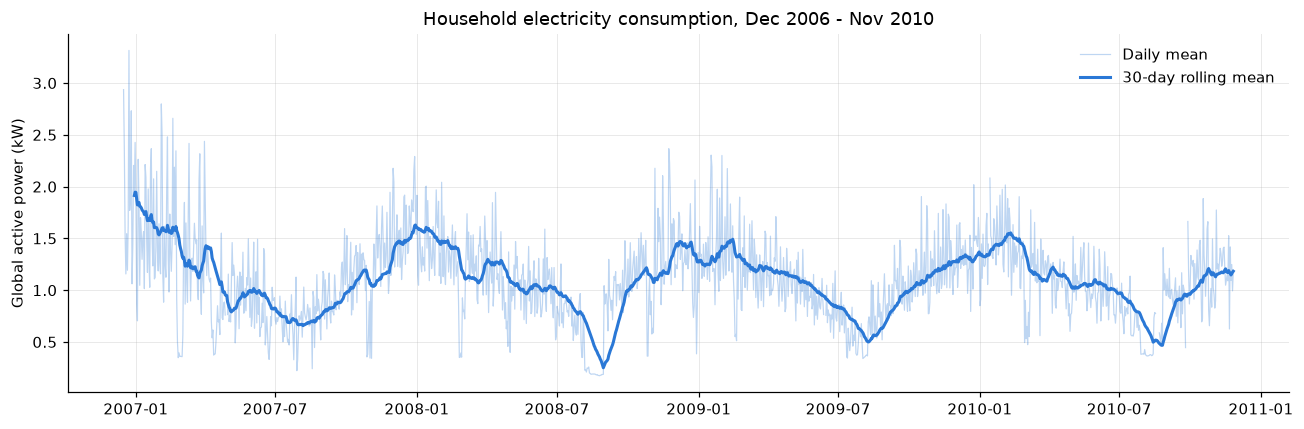

In [11]:
daily = target.resample("D").mean()
monthly_trend = daily.rolling(30, min_periods=15).mean()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(daily.index, daily, color=BLUE, alpha=0.3, linewidth=0.8, label="Daily mean")
ax.plot(monthly_trend.index, monthly_trend, color=BLUE, linewidth=2, label="30-day rolling mean")
ax.set_title("Household electricity consumption, Dec 2006 - Nov 2010")
ax.set_ylabel("Global active power (kW)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

/var/folders/55/bpnz_y1d7h983b05s9zgmpbw0000gn/T/ipykernel_20697/1276355344.py:7: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  if day.dayofweek >= 5:


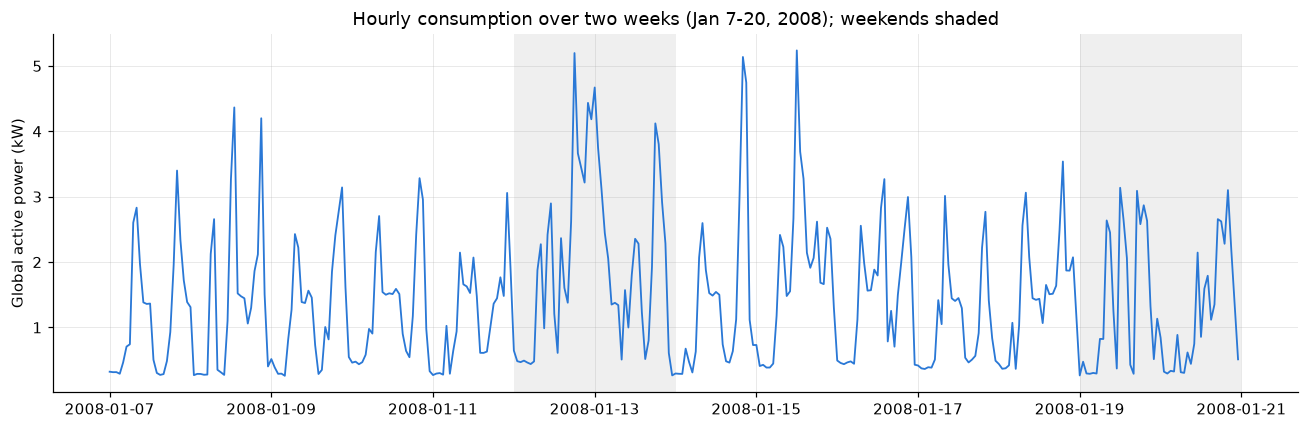

In [12]:
two_weeks = target["2008-01-07":"2008-01-20"]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(two_weeks.index, two_weeks, color=BLUE)

for day in pd.date_range("2008-01-07", "2008-01-20", freq="D"):
    if day.dayofweek >= 5:
        ax.axvspan(day, day + pd.Timedelta(days=1), color="grey", alpha=0.12, linewidth=0)

ax.set_title("Hourly consumption over two weeks (Jan 7-20, 2008); weekends shaded")
ax.set_ylabel("Global active power (kW)")
plt.tight_layout()
plt.show()

/var/folders/55/bpnz_y1d7h983b05s9zgmpbw0000gn/T/ipykernel_20697/2218294681.py:3: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  eda["dayofweek"] = eda.index.dayofweek


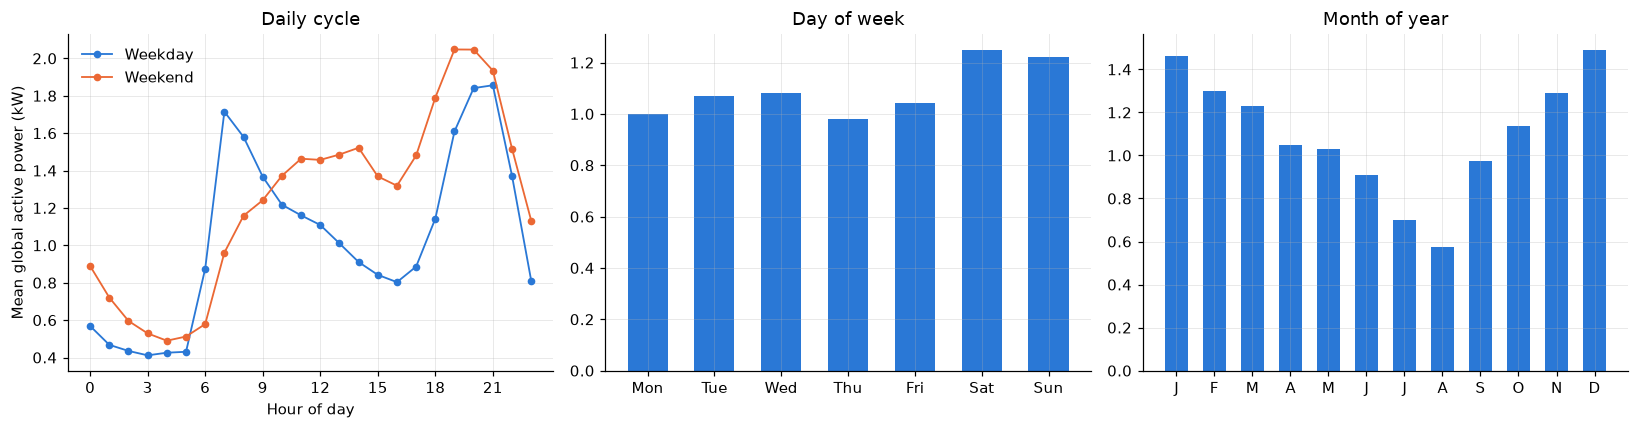

In [13]:
eda = hourly[["Global_active_power"]].dropna().copy()
eda["hour"] = eda.index.hour
eda["dayofweek"] = eda.index.dayofweek
eda["month"] = eda.index.month
eda["is_weekend"] = eda["dayofweek"] >= 5

by_hour = eda.groupby(["hour", "is_weekend"])["Global_active_power"].mean().unstack()
by_dow = eda.groupby("dayofweek")["Global_active_power"].mean()
by_month = eda.groupby("month")["Global_active_power"].mean()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(by_hour.index, by_hour[False], color=BLUE, marker="o", markersize=4, label="Weekday")
axes[0].plot(by_hour.index, by_hour[True], color=ORANGE, marker="o", markersize=4, label="Weekend")
axes[0].set_xticks(range(0, 24, 3))
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("Mean global active power (kW)")
axes[0].set_title("Daily cycle")
axes[0].legend(frameon=False)

axes[1].bar(by_dow.index, by_dow, color=BLUE, width=0.6)
axes[1].set_xticks(range(7))
axes[1].set_xticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
axes[1].set_title("Day of week")

axes[2].bar(by_month.index, by_month, color=BLUE, width=0.6)
axes[2].set_xticks(range(1, 13))
axes[2].set_xticklabels(["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
axes[2].set_title("Month of year")

plt.tight_layout()
plt.show()

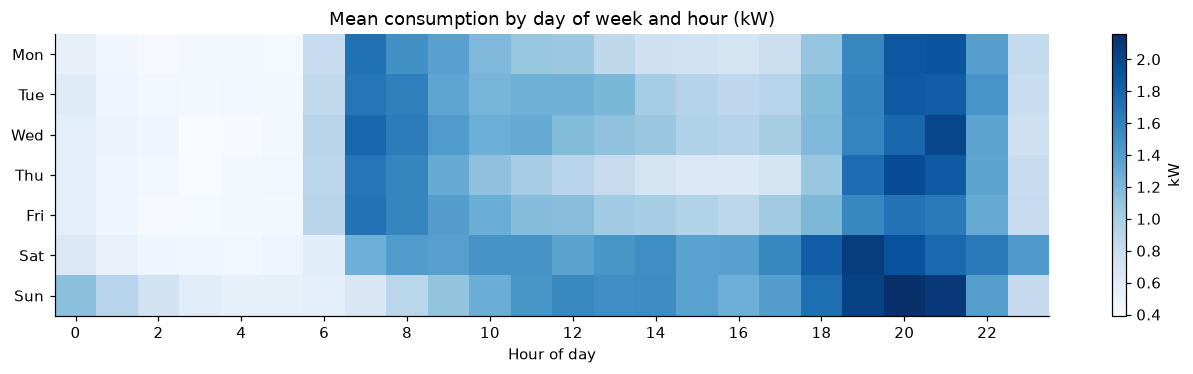

In [14]:
heat = eda.pivot_table(index="dayofweek", columns="hour", values="Global_active_power", aggfunc="mean")

fig, ax = plt.subplots(figsize=(12, 3.5))
im = ax.imshow(heat, aspect="auto", cmap="Blues")
ax.set_yticks(range(7))
ax.set_yticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Hour of day")
ax.set_title("Mean consumption by day of week and hour (kW)")
ax.grid(False)
fig.colorbar(im, ax=ax, label="kW")
plt.tight_layout()
plt.show()

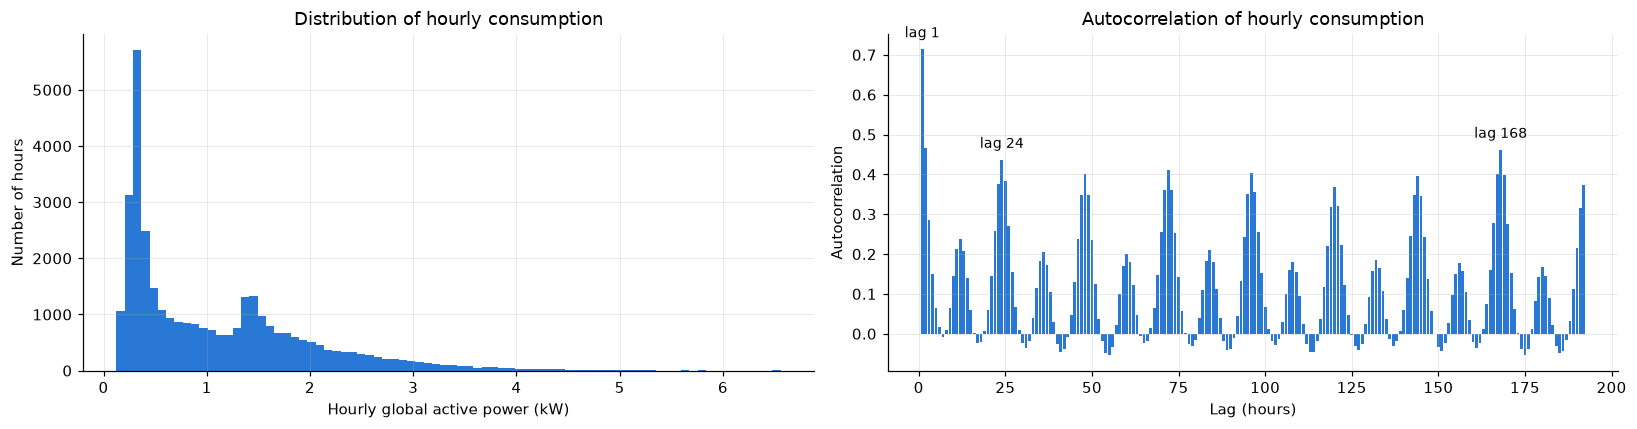

count    34157.000
mean         1.092
std          0.898
min          0.124
25%          0.342
50%          0.803
75%          1.579
max          6.561
Name: Global_active_power, dtype: float64
lag   1 小时的自相关: 0.713
lag   2 小时的自相关: 0.465
lag  24 小时的自相关: 0.436
lag 168 小时的自相关: 0.461


In [15]:
lags = range(1, 24 * 8 + 1)
acf = [target.autocorr(lag) for lag in lags]

fig, axes = plt.subplots(1, 2, figsize=(15, 4))

axes[0].hist(target.dropna(), bins=80, color=BLUE)
axes[0].set_xlabel("Hourly global active power (kW)")
axes[0].set_ylabel("Number of hours")
axes[0].set_title("Distribution of hourly consumption")

axes[1].bar(lags, acf, color=BLUE, width=0.8)
for lag in [1, 24, 168]:
    axes[1].annotate(f"lag {lag}", xy=(lag, acf[lag - 1]), xytext=(0, 8),
                     textcoords="offset points", ha="center", fontsize=9)
axes[1].set_xlabel("Lag (hours)")
axes[1].set_ylabel("Autocorrelation")
axes[1].set_title("Autocorrelation of hourly consumption")

plt.tight_layout()
plt.show()

print(target.describe().round(3))
for lag in [1, 2, 24, 168]:
    print(f"lag {lag:>3} 小时的自相关: {target.autocorr(lag):.3f}")

### EDA observations

（在这里用你自己的话写下从图里看到的规律）